### What is Simple Linear Regression?

- **Simple Linear Regression (SLR)** is a supervised machine learning algorithm used to predict a continuous numerical value.
- It uses **one independent variable (X)** to predict one dependent variable (y).
- It finds the best-fit straight line that represents the relationship between X and y.
- The model learns two parameters: **slope (m)** and **intercept (c)**.
- It minimizes the sum of squared differences between actual and predicted values using the least squares method.


**Equation:**

### $$
\hat{y} = mx + b
$$

Where:
- $\hat{y}$ = Predicted value
- $x$ = Input feature
- $m$ = Slope of the line
- $b$ = Intercept OR 

**Example:** Predicting a student's placement package using their CGPA.


### Simple Linear Regression & Regression Metrics

**ML Journey · Beginner Notes**

This notebook explores how to predict a student's placement package from CGPA using **Simple Linear Regression**. It covers data visualization, train/test splitting, model training, predictions, the slope and intercept, a small from-scratch implementation, regression evaluation metrics, and why adding useful or random features affects model performance.

#### Before you start
- Keep `placement.csv` in the same folder as this notebook.
- The CSV should contain `cgpa` and `package` columns. `package` is measured in LPA (lakhs per annum).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 1. Load and inspect the data

`X` (features) contains the information used to make predictions. `y` (target) is the value we want to predict.

In [2]:
df = pd.read_csv("placement.csv")
display(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


Dataset shape: (200, 2)
Columns: ['cgpa', 'package']


### 2. Explore the relationship between CGPA and package

A scatter plot helps us see whether package tends to increase as CGPA increases. A visible trend can suggest a linear relationship, but it does not prove causation.

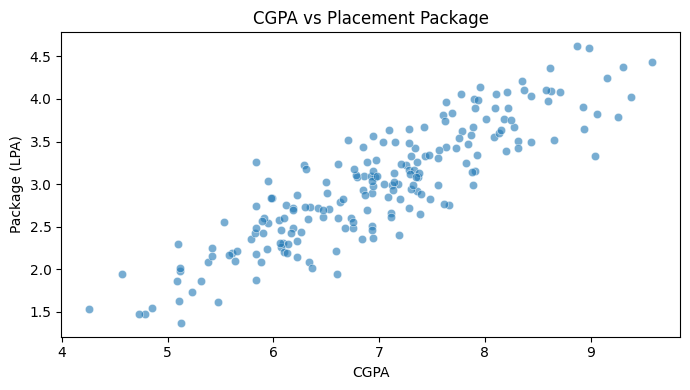

In [3]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="cgpa", y="package", alpha=0.6)
plt.xlabel("CGPA")
plt.ylabel("Package (LPA)")
plt.title("CGPA vs Placement Package")
plt.tight_layout()
plt.show()

### 3. Select features and split the data

We use CGPA as the single input feature and package as the target. `test_size=0.1` reserves 10% of rows for evaluation. `random_state=2` makes the split reproducible.

In [4]:
X = df[["cgpa"]]
y = df["package"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=2
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 180
Testing rows: 20


### 4. Train a Linear Regression model

The model learns a straight line from the training data:

$$
\hat{y} = mx + b
$$

- `m` is the slope (coefficient).
- `b` is the intercept.
- `x` is CGPA and `ŷ` is the predicted package.

In [5]:
lr = LinearRegression()
lr.fit(X_train, y_train)

print("Slope (m):", lr.coef_[0])
print("Intercept (b):", lr.intercept_)

Slope (m): 0.5647691776423975
Intercept (b): -0.9522331404870048


### 5. Make predictions

Predictions are estimates, not guaranteed actual packages. Compare predictions with `y_test` to see how the model performs on unseen rows.

In [6]:
y_pred = lr.predict(X_test)

comparison = pd.DataFrame({
    "CGPA": X_test["cgpa"].values,
    "Actual package (LPA)": y_test.values,
    "Predicted package (LPA)": y_pred
})
display(comparison.head())

,CGPA,Actual package (LPA),Predicted package (LPA)
0,8.58,4.10,3.893486
1,7.15,3.49,3.085866
2,5.88,2.08,2.368610
3,6.22,2.33,2.560631
4,4.57,1.94,1.628762


#### Plot the fitted regression line

The line is drawn over the range of CGPA values. Sorting the x-values first ensures the line is plotted in the correct order.

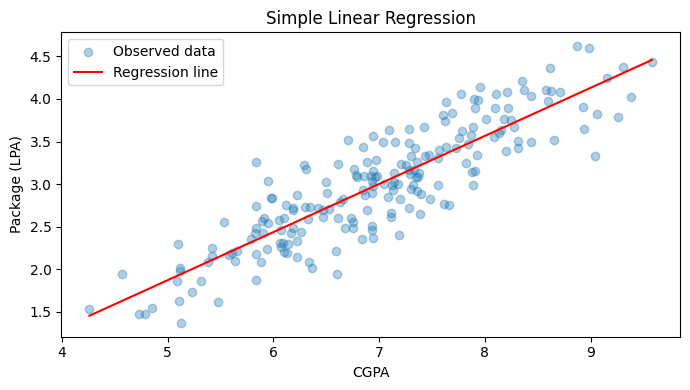

In [7]:
plt.figure(figsize=(7, 4))
plt.scatter(df["cgpa"], df["package"], alpha=0.35, label="Observed data")

line_x = pd.DataFrame({
    "cgpa": np.linspace(df["cgpa"].min(), df["cgpa"].max(), 100)
})
plt.plot(line_x["cgpa"], lr.predict(line_x), color="red", label="Regression line")
plt.xlabel("CGPA")
plt.ylabel("Package (LPA)")
plt.title("Simple Linear Regression")
plt.legend()
plt.tight_layout()
plt.show()

#### Use the learned equation for a new CGPA

This calculates an estimate using the model's learned slope and intercept.

In [8]:
m = lr.coef_[0]
b = lr.intercept_

cgpa_value = 8.99
predicted_package = m * cgpa_value + b
print(f"Estimated package for CGPA {cgpa_value}: {predicted_package:.2f} LPA")

# The model can also predict directly:
print("Model prediction:", lr.predict(pd.DataFrame({"cgpa": [cgpa_value]}))[0])

Estimated package for CGPA 8.99: 4.13 LPA
Model prediction: 4.125041766518149


### 6. Implement Simple Linear Regression from scratch

For one feature, the slope is calculated from the covariance-like sum divided by the squared deviations of `x`. The intercept makes the fitted line pass through the means of `x` and `y`.

This small class is for learning. In normal projects, prefer the tested implementation in scikit-learn.

In [9]:
class SimpleLR:
    def __init__(self):
        self.m = None
        self.b = None

    def fit(self, X_train, y_train):
        # Convert one-column DataFrame/Series or arrays into 1D arrays.
        x = np.asarray(X_train).reshape(-1)
        y = np.asarray(y_train).reshape(-1)

        if len(x) != len(y):
            raise ValueError("X_train and y_train must have the same number of rows.")
        if len(x) < 2:
            raise ValueError("At least two training rows are required.")

        x_mean = x.mean()
        y_mean = y.mean()

        denominator = np.sum((x - x_mean) ** 2)
        if denominator == 0:
            raise ValueError("CGPA values must not all be identical.")

        self.m = np.sum((x - x_mean) * (y - y_mean)) / denominator
        self.b = y_mean - self.m * x_mean
        return self

    def predict(self, X):
        if self.m is None or self.b is None:
            raise ValueError("Call fit() before predict().")
        x = np.asarray(X).reshape(-1)
        return self.m * x + self.b

In [10]:
manual_lr = SimpleLR().fit(X_train, y_train)

print("From-scratch slope:", manual_lr.m)
print("From-scratch intercept:", manual_lr.b)
print("First test prediction:", manual_lr.predict(X_test.iloc[[0]])[0])

From-scratch slope: 0.5647691776423972
From-scratch intercept: -0.9522331404870026
First test prediction: 3.8934864036847654


### 7. Evaluate regression performance

Metrics summarize different kinds of prediction error. Lower MAE, MSE, and RMSE generally mean smaller errors; a higher R² is generally better.

In [13]:
# Evaluate the scikit-learn model on the test set.
y_pred = lr.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.4f} LPA")
print(f"MSE  : {mse:.4f} (LPA squared)")
print(f"RMSE : {rmse:.4f} LPA")
print(f"R²   : {r2:.4f}")

MAE  : 0.2653 LPA
MSE  : 0.0951 (LPA squared)
RMSE : 0.3084 LPA
R²   : 0.8511


### What do these metrics mean?

- **MAE (Mean Absolute Error):** average absolute difference between actual and predicted values. It uses the target's units (LPA).
- **MSE (Mean Squared Error):** average squared error. Larger errors receive a stronger penalty.
- **RMSE (Root Mean Squared Error):** square root of MSE, so it returns to the target's units (LPA).
- **R² (R-squared):** compares the model with predicting the target mean. It can be negative on test data if the model performs worse than that baseline; 1 is a perfect fit.

**Adjusted R²** penalizes adding extra features that do not improve the model enough. For `n` observations and `p` input features:

$$
R^2_{adj} = 1 - (1-R^2)\frac{n-1}{n-p-1}
$$ 

Adjusted R² needs `n > p + 1`. It is useful when comparing models with different numbers of features.

In [14]:
def adjusted_r2_score(r2, n_rows, n_features):
    if n_rows <= n_features + 1:
        return np.nan
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)

n_test = X_test.shape[0]
p = X_test.shape[1]
print(f"Adjusted R²: {adjusted_r2_score(r2, n_test, p):.4f}")

Adjusted R²: 0.8428


### 8. Experiment: add a random feature

A random feature has no meaningful relationship with the target. We add one to see why more columns do not automatically make a model better.

This experiment is intentionally random; its exact results can vary between runs. Use a fixed seed for repeatability.

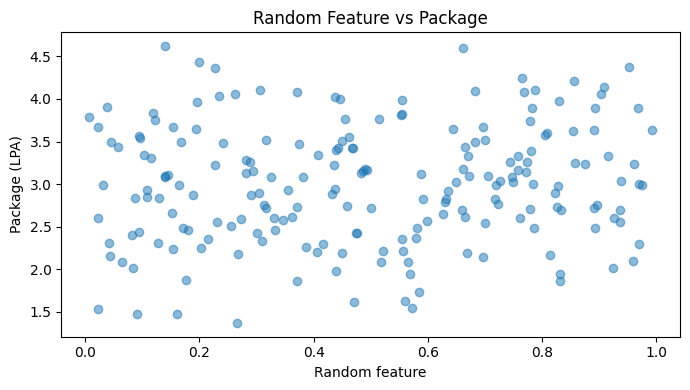

In [15]:
rng = np.random.default_rng(42)
df_random = df[["cgpa", "package"]].copy()
df_random["random_feature"] = rng.random(len(df_random))

plt.figure(figsize=(7, 4))
plt.scatter(df_random["random_feature"], df_random["package"], alpha=0.5)
plt.xlabel("Random feature")
plt.ylabel("Package (LPA)")
plt.title("Random Feature vs Package")
plt.tight_layout()
plt.show()

In [16]:
X_random = df_random[["cgpa", "random_feature"]]
y = df_random["package"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_random, y, test_size=0.1, random_state=2
)

random_feature_model = LinearRegression().fit(X_train_r, y_train_r)
pred_random = random_feature_model.predict(X_test_r)

r2_random = r2_score(y_test_r, pred_random)
adj_r2_random = adjusted_r2_score(r2_random, len(y_test_r), X_test_r.shape[1])

print(f"R² with CGPA + random feature: {r2_random:.4f}")
print(f"Adjusted R²: {adj_r2_random:.4f}")

R² with CGPA + random feature: 0.8516
Adjusted R²: 0.8341


### 9. Experiment: add a target-related feature

Here we create a synthetic `iq` column using the package plus small random noise. Because this feature is constructed from the target, it contains information derived directly from the answer. This is **target leakage** and is not a valid real-world predictor.

This experiment demonstrates that a feature strongly related to the target can inflate performance, but it should not be used as a legitimate prediction setup.

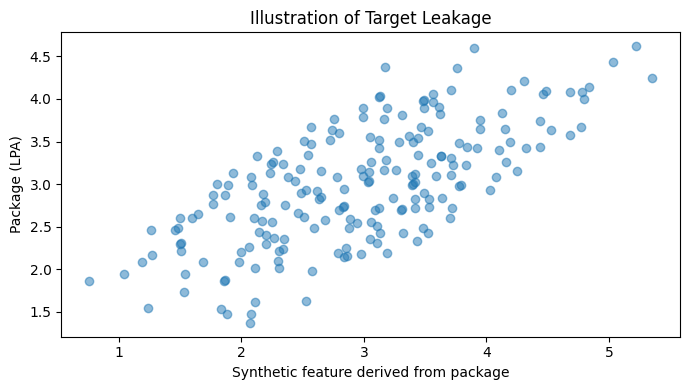

In [17]:
rng = np.random.default_rng(42)
df_leakage = df[["cgpa", "package"]].copy()
df_leakage["synthetic_iq"] = (
    df_leakage["package"] + rng.integers(-12, 12, size=len(df_leakage)) / 10
)

plt.figure(figsize=(7, 4))
plt.scatter(df_leakage["synthetic_iq"], df_leakage["package"], alpha=0.5)
plt.xlabel("Synthetic feature derived from package")
plt.ylabel("Package (LPA)")
plt.title("Illustration of Target Leakage")
plt.tight_layout()
plt.show()

In [18]:
X_leak = df_leakage[["cgpa", "synthetic_iq"]]
y_leak = df_leakage["package"]

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_leak, y_leak, test_size=0.1, random_state=2
)

leakage_model = LinearRegression().fit(X_train_l, y_train_l)
pred_leak = leakage_model.predict(X_test_l)

r2_leak = r2_score(y_test_l, pred_leak)
adj_r2_leak = adjusted_r2_score(r2_leak, len(y_test_l), X_test_l.shape[1])

print(f"R² with leakage feature: {r2_leak:.4f}")
print(f"Adjusted R²: {adj_r2_leak:.4f}")

R² with leakage feature: 0.8625
Adjusted R²: 0.8463


### Key takeaways

- Simple Linear Regression models a straight-line relationship between one input feature and a numeric target.
- Split data into training and testing sets to evaluate predictions on unseen examples.
- The coefficient is the slope; the intercept is the predicted value when the input is zero.
- MAE, MSE, RMSE, and R² describe model performance in different ways.
- Adjusted R² accounts for the number of input features.
- Adding random features does not guarantee improvement.
- Avoid **target leakage** : never use a feature that is created from, or would only be known after observing, the target.